# Email / SMS Spam Detection
**Oasis Infobyte SIP — Data Science Task 4** · Steven Manuel Rios

Dataset: **SMS Spam Collection**, UCI Machine Learning Repository (`data/SMSSpamCollection`, 5,572 labelled messages).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

       count  percent
label                
ham     4825    86.59
spam     747    13.41


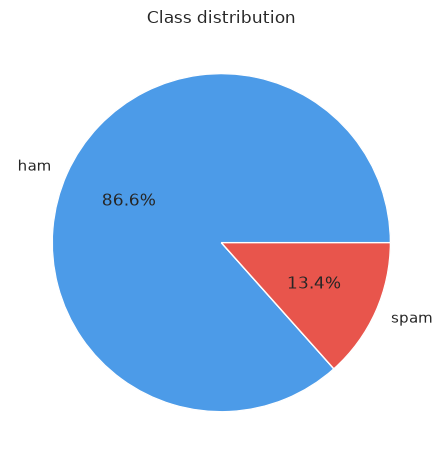

In [2]:
df = pd.read_csv("data/SMSSpamCollection", sep="\t", header=None, names=["label", "text"])
counts = df["label"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))
counts.plot.pie(autopct="%1.1f%%", colors=["#4c9be8", "#e8554c"], title="Class distribution"); plt.ylabel(""); save("class_distribution")

The classes are **imbalanced**: about 87% ham and 13% spam. Accuracy alone would therefore be misleading, because predicting 'ham' every time already scores about 87%.

## 1. Preprocessing pipeline
lowercase → strip URLs, numbers and punctuation → remove stop-words → Porter stemming

In [3]:
import re
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
stem = PorterStemmer().stem
def clean(t):
    t = t.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " url ", t)
    t = re.sub(r"\d+", " num ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return " ".join(stem(w) for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 1)
df["clean"] = df["text"].apply(clean)
df["y"] = (df["label"] == "spam").astype(int)
df[["text", "clean"]].head()

,text,clean
0,"Go until jurong point, crazy.. Available only ...",jurong point crazi avail bugi great world la b...
1,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri num wkli comp win fa cup final tkt ...
3,U dun say so early hor... U c already then say...,dun say earli hor say
4,"Nah I don't think he goes to usf, he lives aro...",nah don think goe usf live


## 2. TF-IDF features
**TF-IDF (Term Frequency × Inverse Document Frequency)** scores how important a word is to one message relative to the whole corpus. *TF* counts how often the word appears in that message. *IDF* = log(N / number of messages containing the word), which down-weights words that appear everywhere, such as 'call' or 'ok', and up-weights distinctive ones, such as 'prize' or 'claim'. Each message becomes a sparse vector of these weights.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df["clean"], df["y"], test_size=0.2, random_state=42, stratify=df["y"])
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
Xtr, Xte = vec.fit_transform(X_train), vec.transform(X_test)
Xtr.shape

(4457, 6794)

## 3. Classifiers: Multinomial Naive Bayes, Logistic Regression, Linear SVM

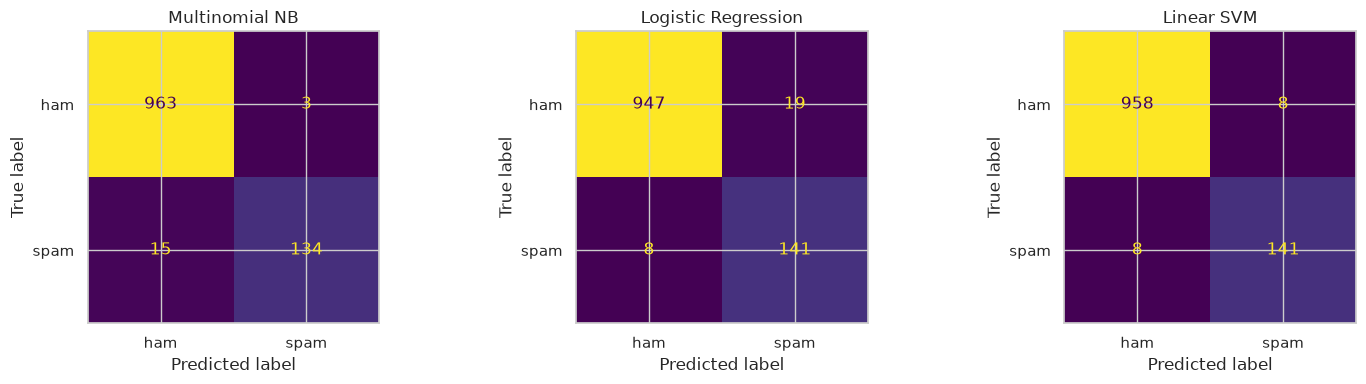

,Accuracy,Precision,Recall,F1
Model,,,,
Multinomial NB,0.9839,0.9781,0.8993,0.9371
Logistic Regression,0.9758,0.8812,0.9463,0.9126
Linear SVM,0.9857,0.9463,0.9463,0.9463


In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
models = {"Multinomial NB": MultinomialNB(alpha=0.1),
          "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
          "Linear SVM": LinearSVC(class_weight="balanced")}
rows = []; fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n, m) in zip(axes, models.items()):
    m.fit(Xtr, y_train); p = m.predict(Xte)
    rows.append({"Model": n, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=["ham", "spam"], ax=ax, colorbar=False); ax.set_title(n)
save("confusion_matrices")
pd.DataFrame(rows).set_index("Model").round(4)

## 4. Why recall matters for spam detection
**Recall** is the share of actual spam that the filter catches. Every spam message it misses (a false negative) lands in the inbox, and that is how phishing links, scams and malware reach users. Low recall means the filter is failing at its main job. Recall still has to be balanced against **precision**: flagging a real message as spam (a false positive) can hide something important, such as a bank OTP or a job offer. So I compare models on recall *together with* precision and F1. Here, **Linear SVM** gives the best balance (recall ≈ 0.95 with precision ≈ 0.95, the best F1). Naive Bayes is the most precise but misses about 10% of spam. Logistic Regression catches as much spam as the SVM but raises more false alarms.

## 5. (Bonus) Word clouds

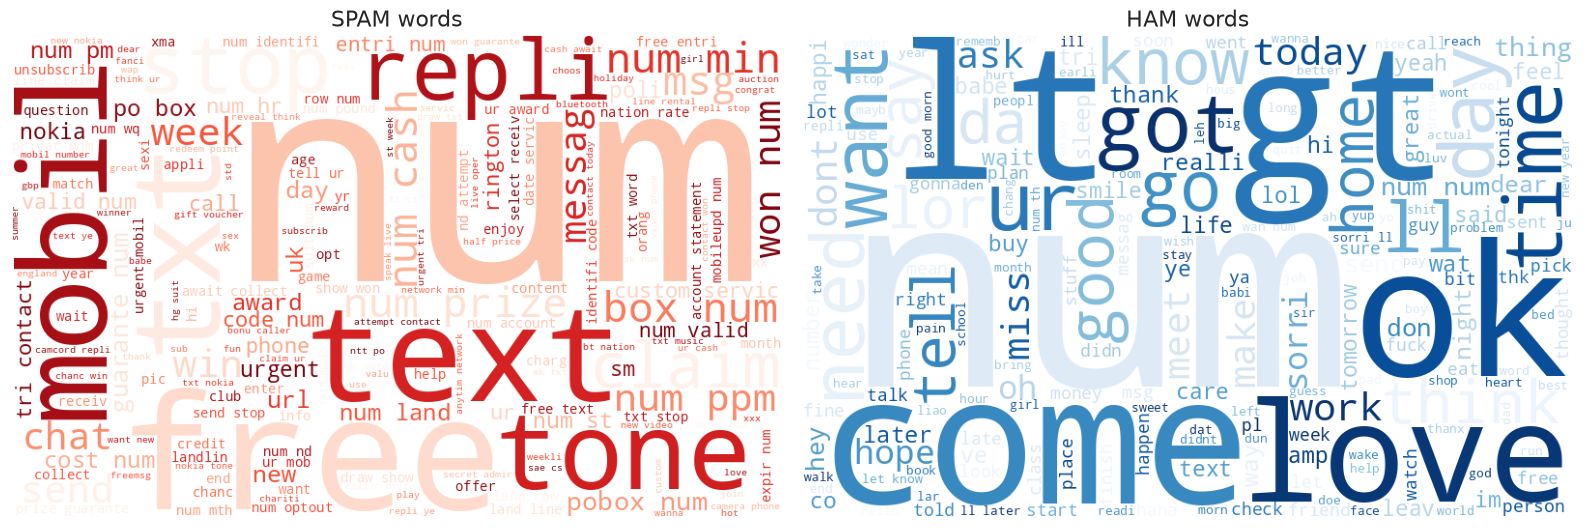

In [6]:
from wordcloud import WordCloud
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, (lab, cmap) in zip(ax, [(1, "Reds"), (0, "Blues")]):
    wc = WordCloud(width=800, height=500, background_color="white", colormap=cmap).generate(" ".join(df[df.y == lab]["clean"]))
    a.imshow(wc); a.axis("off"); a.set_title("SPAM words" if lab else "HAM words", fontsize=16)
save("wordclouds")